# Factor-view convergence diagnostics

Repeat the same evidence, personality, and model **10 times** to inspect Q variability and running-mean stability. Factors are discovered from the catalog; Q rows are matched through `activeFactors`, not their row positions in the full catalog. Abstentions are missing values, **never zero returns**.

These diagnostics measure empirical repeatability, not forecast accuracy or proof of convergence. Ten observations are a starting point, not a convergence threshold. A stable mean can coexist with highly variable individual outputs.

Select a Python kernel and install `notebook-requirements.txt` into that environment if needed. Set `OPENAI_API_KEY` securely in the kernel environment; never put credentials in notebook cells. The live-run cell makes billable API calls.

In [23]:
import json
import os
import sys
from copy import deepcopy
from datetime import datetime, timezone
from pathlib import Path
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import MaxNLocator, PercentFormatter

root_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (path for path in root_candidates
     if (path / 'backend' / 'app' / 'services' / 'orchestrators'
         / 'factor_view_orchestrator.py').is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError('Open this notebook with agent_validator as the working directory.')
backend_path = str(ROOT / 'backend')
if backend_path not in sys.path:
    sys.path.insert(0, backend_path)

from app.services.factor_view_prompts import DEFAULT_PERSONALITY_KEY
from app.services.orchestrators.factor_view_orchestrator import (
    DEFAULT_SNAPSHOT_PATH,
    FACTOR_DEFINITIONS_PATH,
    generate_factor_views,
)


10 calls | Long-Horizon Analyst with Adaptive Short-Term Adjustment | openai:gpt-4o | evidence as of 2026-10-01


In [35]:
def save_checkpoint(output_path, payload):
    text = json.dumps(payload, ensure_ascii=False, indent=2, allow_nan=False) + '\n'
    temporary_path = output_path.with_name(f'.{output_path.name}.{uuid4().hex}.tmp')
    try:
        with temporary_path.open('x', encoding='utf-8') as stream:
            stream.write(text)
        temporary_path.replace(output_path)
    finally:
        temporary_path.unlink(missing_ok=True)


def collect_runs(n, snapshot, factor_order, personality_key, model, *, output_path=None, generate=generate_factor_views):
    if isinstance(n, bool) or not isinstance(n, int) or n < 1:
        raise ValueError('n must be a positive integer.')
    records, responses = [], []
    started = datetime.now(timezone.utc)
    if output_path is None:
        output_path = OUTPUT_DIR / f'factor_views_{started:%Y%m%dT%H%M%S}_{uuid4().hex}.json'
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    payload = {
        'startedAt': started.isoformat(),
        'requestedIterations': n,
        'completedIterations': 0,
        'complete': False,
        'personalityKey': personality_key,
        'model': model,
        'factorOrder': list(factor_order),
        'evidenceSnapshot': deepcopy(snapshot),
        'responses': responses,
    }
    initial_json = json.dumps(payload, ensure_ascii=False, indent=2, allow_nan=False) + '\n'
    with output_path.open('x', encoding='utf-8') as stream:
        stream.write(initial_json)
    print(f'Saving full responses to: {output_path.resolve()}')
    for run in range(1, n + 1):
        response = generate(
            deepcopy(snapshot), personality_key=personality_key, model=model
        )
        if response['factorOrder'] != factor_order:
            raise ValueError(f'Factor catalog changed at run {run}; restart with fixed inputs.')
        if responses and any(
            response[key] != responses[0][key]
            for key in ('asOf', 'targetHorizon', 'qReturnConvention')
        ):
            raise ValueError(f'Return context changed at run {run}; do not combine these runs.')
        active_q = {
            factor: row[0]
            for factor, row in zip(response['activeFactors'], response['Q'], strict=True)
        }
        if not all(np.isfinite(value) for value in active_q.values()):
            raise ValueError(f'Non-finite Q value at run {run}.')
        records.append({factor: active_q.get(factor, np.nan) for factor in factor_order})
        responses.append(response)
        payload['completedIterations'] = run
        payload['complete'] = run == n
        save_checkpoint(output_path, payload)
        print(f'Run {run:>3}/{n}: {len(active_q)}/{len(factor_order)} active views')
    frame = pd.DataFrame(records, columns=factor_order, dtype=float)
    frame.index = pd.RangeIndex(1, n + 1, name='Run')
    return frame, responses


def summarize_runs(q_values):
    summary = pd.DataFrame({
        'Active': q_values.count(),
        'Abstained': q_values.isna().sum(),
        'Active fraction': q_values.notna().mean(),
        'Mean Q': q_values.mean(),
        'Sample std Q': q_values.std(ddof=1),
        'Min Q': q_values.min(),
        'Max Q': q_values.max(),
    })
    summary.index.name = 'Factor'
    return summary


In [36]:
def plot_convergence(q_values, convention, horizon):
    factors = list(q_values.columns)
    fig, axes = plt.subplots(
        len(factors), 3, figsize=(16, 3.5 * len(factors)),
        squeeze=False, layout='constrained', facecolor='white',
    )
    colors = plt.get_cmap('tab10')
    run_numbers = q_values.index.to_numpy()
    for index, factor in enumerate(factors):
        values = q_values[factor]
        active = values.dropna()
        color = colors(index % 10)
        trace_ax, distribution_ax, coverage_ax = axes[index]
        trace_ax.plot(run_numbers, values, 'o-', color=color, alpha=0.55, label='Individual Q')
        running_mean = values.expanding().mean()
        trace_ax.plot(run_numbers, running_mean, color=color, linewidth=2.5, label='Running mean (active only)')
        trace_ax.axhline(0, color='gray', linewidth=0.8, linestyle=':')
        trace_ax.set(title=f'{factor} | Q across calls', xlabel='Call number', ylabel='Expected return')
        trace_ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
        trace_ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        trace_ax.legend(fontsize=8, loc='best')

        if not active.empty:
            box = distribution_ax.boxplot(active.to_numpy(), patch_artist=True, widths=0.35)
            box['boxes'][0].set(facecolor=color, alpha=0.25)
            offsets = np.linspace(-0.08, 0.08, len(active)) if len(active) > 1 else np.zeros(1)
            distribution_ax.scatter(1 + offsets, active.to_numpy(), color=color, alpha=0.8, zorder=3)
        else:
            distribution_ax.text(0.5, 0.5, 'All calls abstained', ha='center', va='center', transform=distribution_ax.transAxes)
        distribution_ax.set(title=f'{factor} | Active-Q distribution', xticks=[], ylabel='Expected return')
        distribution_ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

        coverage = values.notna().cumsum() / run_numbers
        coverage_ax.plot(run_numbers, coverage, 'o-', color=color, linewidth=2)
        coverage_ax.set(
            title=f'{factor} | {len(active)} active, {values.isna().sum()} abstained',
            xlabel='Call number', ylabel='Cumulative active-view fraction', ylim=(-0.03, 1.03),
        )
        coverage_ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
        coverage_ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        for ax in axes[index]:
            ax.grid(axis='y', alpha=0.18)
            ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle(
        f'Factor-view repeatability | {len(q_values)} calls | {horizon} | {convention}',
        fontsize=15, fontweight='bold',
    )
    return fig


In [37]:
N = 10
PERSONALITY_KEY = "Long-Horizon Analyst with Adaptive Short-Term Adjustment"
MODEL = os.environ.get('OPENAI_MODEL', 'openai:gpt-4o')
SNAPSHOT_PATH = DEFAULT_SNAPSHOT_PATH
OUTPUT_DIR = ROOT / 'convergence_results'

snapshot = json.loads(SNAPSHOT_PATH.read_text(encoding='utf-8'))
factor_definitions = json.loads(FACTOR_DEFINITIONS_PATH.read_text(encoding='utf-8'))
factor_order = [factor['key'] for factor in factor_definitions]
if not factor_order:
    raise ValueError('The factor catalog must contain at least one factor to plot.')
print(f'{N} calls | {PERSONALITY_KEY} | {MODEL} | evidence as of {snapshot["asOf"]}')

10 calls | Long-Horizon Analyst with Adaptive Short-Term Adjustment | openai:gpt-4o | evidence as of 2026-10-01


## Run the experiment

**The next cell makes N live API calls.** Keep the snapshot, personality, model, catalog, prompts, and runtime configuration unchanged throughout the batch. Calls are sequential, without a fixed seed or reused responses. Full validated responses are retained in `responses` for inspection.

All full responses, including rationales, confidence, P, and Q, are saved in a single uniquely named JSON under `OUTPUT_DIR`. The file also includes the evidence snapshot, model, personality, and requested/completed iteration counts. It is checkpointed atomically after every successful iteration. A stopped batch retains completed responses with `complete: false`; a successful batch has `complete: true`. Existing files are never reused when starting a batch.

Errors stop the batch explicitly; no failures are silently skipped, imputed, or retried. A failed batch may already have incurred API costs, and rerunning it starts a fresh batch. No live calls are needed to define the helpers above.

In [38]:
q_values, responses = collect_runs(
    N, snapshot, factor_order, PERSONALITY_KEY, MODEL
)


Saving full responses to: C:\work\agent_validator\convergence_results\factor_views_20261019T003058_058fbdfbf03246a3beaff8113e0776ec.json
Run   1/10: 3/3 active views
Run   2/10: 3/3 active views
Run   3/10: 3/3 active views
Run   4/10: 3/3 active views
Run   5/10: 3/3 active views
Run   6/10: 3/3 active views
Run   7/10: 3/3 active views
Run   8/10: 3/3 active views
Run   9/10: 3/3 active views
Run  10/10: 3/3 active views


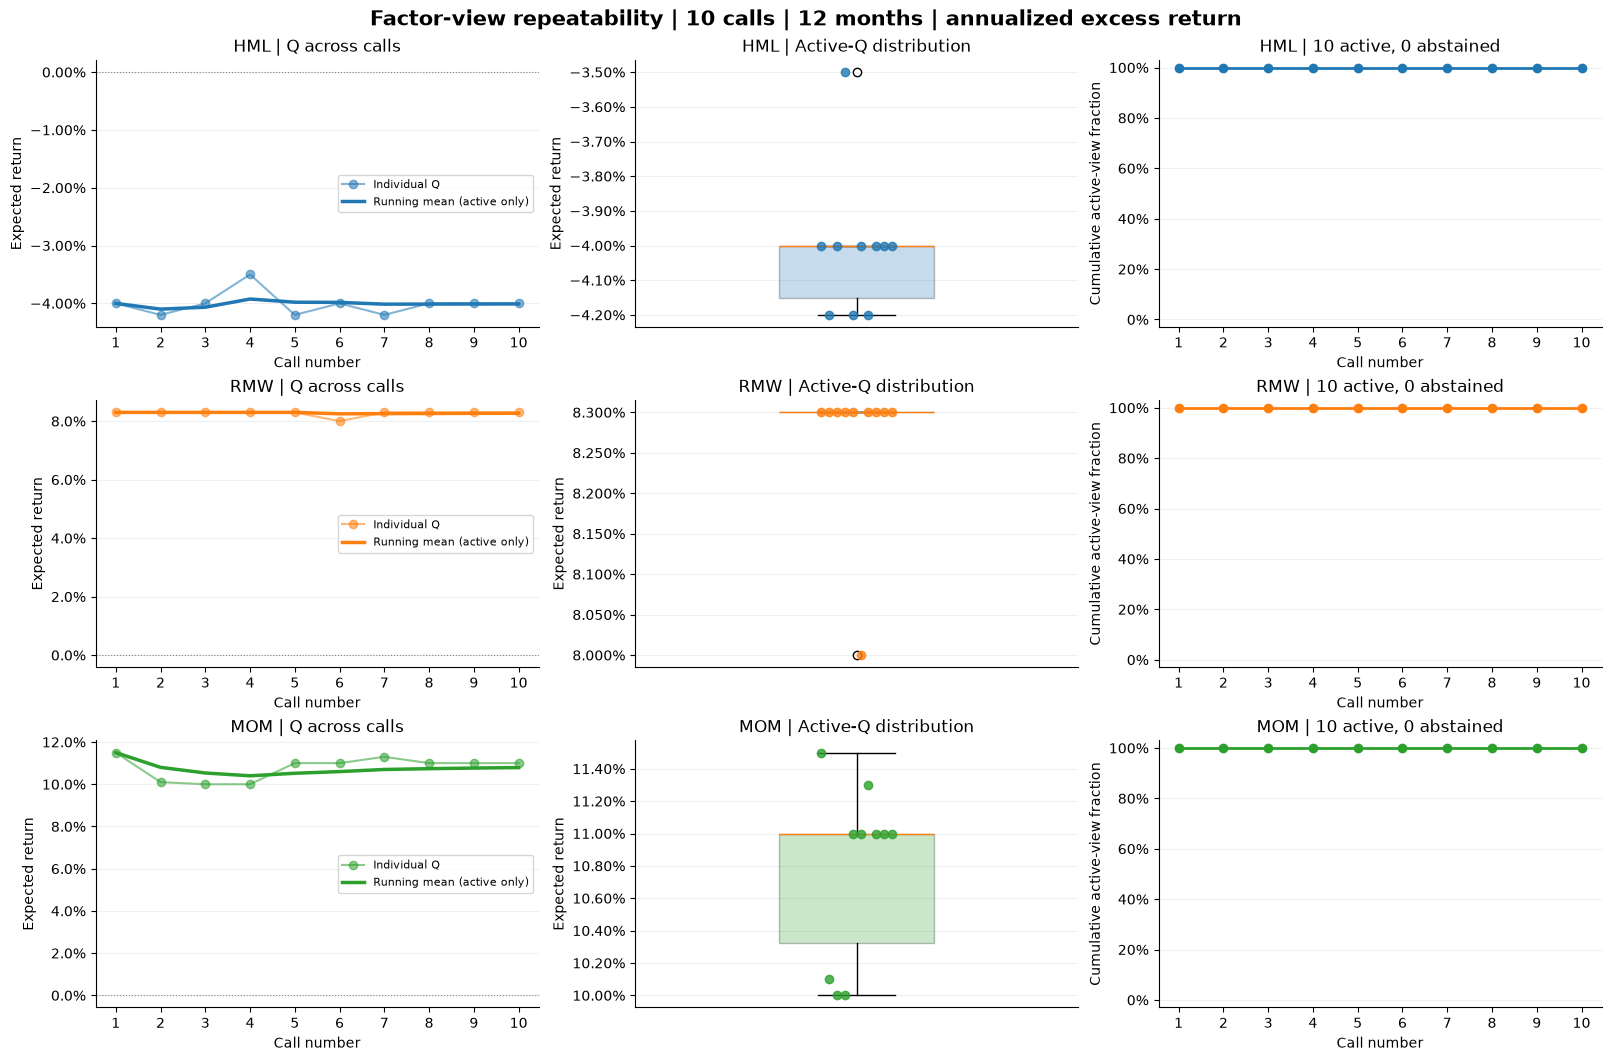

,Active,Abstained,Active fraction,Mean Q,Sample std Q,Min Q,Max Q
Factor,,,,,,,
HML,10,0,100.00%,-4.01%,0.20%,-4.20%,-3.50%
RMW,10,0,100.00%,8.27%,0.09%,8.00%,8.30%
MOM,10,0,100.00%,10.79%,0.55%,10.00%,11.50%


In [39]:
figure = plot_convergence(
    q_values, responses[0]['qReturnConvention'], responses[0]['targetHorizon']
)
plt.show()

summary = summarize_runs(q_values)
display(summary.style.format(
    {column: '{:.2%}' for column in
     ['Active fraction', 'Mean Q', 'Sample std Q', 'Min Q', 'Max Q']},
    na_rep='Unavailable',
))


## Reading the diagnostics

- **Left:** individual Q estimates and the cumulative mean of active views. Gaps in the individual trace denote abstentions; a running mean carried across an abstention adds no new estimate.
- **Middle:** the active-output distribution and every observed point. Persistent spread or sign changes indicate output variability even if the mean settles.
- **Right:** cumulative coverage. A stable active-only mean with frequent abstentions is not stable overall behavior.
- **Table:** Q statistics exclude abstentions. Sample standard deviation uses `ddof=1` and is undefined with fewer than two active observations. All-abstained factors have undefined Q statistics, not zero returns.

Increase N to assess repeatability more thoroughly. Shrinking changes in a running mean are expected from averaging and do not prove convergence, calibrated uncertainty, independence of calls, or economic validity. There is no automatic pass/fail threshold. Change one setting at a time between batches; inspect `q_values` and `responses` when diagnosing outliers or abstention rationales.